# Trotter error under device noise

**Shengjie Xu · October 2026** · code and data: [github.com/jayhsu0627/qtrotter](https://github.com/jayhsu0627/qtrotter) · 4-page write-up with related work: [writeup/writeup.pdf](../writeup/writeup.pdf)

On a noisy quantum computer the number of Trotter steps r is a trade-off, not a precision dial: more steps shrink the
Trotter error but add gates, and gate noise grows with every one of them. So there is an optimal step count r\*. Two
analytic papers predict it from a single uniform gate error rate,
[Knee & Munro (2015)](https://arxiv.org/abs/1502.04536) and [Avtandilyan & Pogosov (2024)](https://arxiv.org/abs/2405.01131).
This notebook reproduces the ingredients, tests those predictions on 1D spin chains of 4 to 12 qubits under the
noise model of IBM's Torino processor, and checks one configuration on a real IBM device.

**Findings**

1. **Error bounds (question 1).** On TFIM and XXZ chains the commutator bound of
   [Childs et al. (2021)](https://arxiv.org/abs/1912.08854) overestimates the worst-case Trotter error by about 6–7× at
   first order and 4× at second order, independent of chain length. The norm bound overestimates it by 10²–10³× at
   orders 1 and 2 and 10⁵–10⁸× at order 4, growing with n. Both match Childs et al.
2. **Predicted optimum (question 2).** Under the Torino noise model, the measured r\* ranges from 1 to 16, growing with
   evolution time. Knee & Munro's formula overshoots it by a median 2.4× and Avtandilyan & Pogosov's by 3.7× (orders
   1 and 2; Knee & Munro's second order is our extension of their general form). To make Knee & Munro's exact, the
   per-step error would have to be about 11–12× the calibrated one.
3. **Why they overshoot.** The Trotter term. Their constant exceeds the initial state's actual one by a median 15× at
   first order and 9× at second. Swapping only that constant inside their own formula removes the overshoot; changing
   only how the two errors combine does not; nor does [Xu et al. (2025)](https://arxiv.org/abs/2504.10247)'s
   refinement, which keeps the worst-case constant and lets late steps' errors decay as the state mixes (it moves
   r\* up by a few percent). A semi-empirical predictor (the state's noiseless Trotter error from a
   classical simulation, plus the calibrated gate errors) lands within one grid step of r\* in all 42 configurations
   with a clear minimum, and in the 3 shallow fourth-order ones too.
4. **Which order.** With two groups of terms, second order's outer half-steps merge (standard Strang splitting), so it
   costs the same two-qubit gates as first order, and it wins at every size and time tested. Avtandilyan & Pogosov's cost
   model charges it double, which is why they find first order optimal at these error rates. Fourth order (5× the
   gates) loses everywhere.
5. **Pitfalls worth knowing.** Passed to Qiskit as one operator, the TFIM's second-order formula is *identical* to
   first order on Z-type observables from |0…0⟩, yet costs 1.7× the two-qubit gates. Single-observable errors are poor
   guides to r\*, because Trotter and noise errors can cancel.
6. **Hardware (question 3).** On `ibm_kingston` (12-qubit chain, 18 circuits, 92 s of device time) the optimum falls
   where the device's own noise model puts it: r\* = 8 at first order and 6–8 at second. The model tracks the device's
   error to within 0.01 at every r, and second order beats first on hardware as well. The semi-empirical predictor,
   adapted to observables, comes out one grid step low (6 and 4), because local observables decay several times slower
   than the whole-state fidelity it assumes; the analytic formulas predict 17 to 34.
7. **Better devices, and a second model (section 5).** With every Torino error rate scaled down by up to 100×, second
   order beats first at every level, and fourth order overtakes second only once errors are 23–31× lower, more than
   the order of magnitude Avtandilyan & Pogosov estimate. The semi-empirical predictor, run before those simulations,
   placed r\* within one grid step in all 45 configurations and picked the better order in 14 of 15. On the XXZ chain
   under noise the same picture holds: the analytic overshoot comes from the Trotter constant, and the predictor lands
   within one step in 30 of 31 configurations with a clear minimum.
8. **Local observables, the light cone and long chains (section 6).** For the RMS error of local observables, r\* is
   within about 15% of the state's at 6 to 12 qubits, and stops depending on the chain length once the chain is
   longer than the light cone. Noise reaches a local observable only from sites within about $vt$ of it, whatever r,
   so its effect grows linearly in r: at second order r\* scales as $\gamma^{-1/3}$, not as the $\gamma^{-1/4}$ of
   [Trivedi & Cirac](https://arxiv.org/abs/2509.17579)'s bound, which counts every gate in the circuit's light cone.
   Fourth order never beats second on local observables, even on a device 100× better than Torino. Light-cone
   patches of 10 qubits find r\* on long chains: they match the full 12-site simulation for t ≤ 2 and 20-qubit
   trajectories, and give the same r\* on a 96-qubit Torino chain.

## 0. Setup

Every number and figure below comes from the CSVs in `results/`, which `scripts/run_noiseless.py`,
`scripts/run_noisy.py`, `scripts/predict_noise_scaling.py`, `scripts/run_noise_response.py`, `scripts/run_patches.py` and
`scripts/run_trajectories.py` regenerate from `config.yaml`. The small demonstrations in section 1 run live.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import yaml

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))

from qtrotter import Model, Propagator, plots, predict, state_metrics, tfim
from qtrotter.circuits import choose_layout, device_circuit, trotter_circuit, two_qubit_count

cfg = yaml.safe_load(open(ROOT / "config.yaml"))
noiseless = pd.read_csv(ROOT / "results/noiseless.csv")
noisy = pd.read_csv(ROOT / "results/noisy.csv")
FIG = ROOT / "figures"
pd.set_option("display.precision", 3)
print(f"{len(noiseless)} noiseless rows, {len(noisy)} noisy rows")

720 noiseless rows, 540 noisy rows


## 1. Models, formulas and two implementation details

Two open chains:

$$H_\mathrm{TFIM} = -J\sum_{i=1}^{n-1} Z_iZ_{i+1} - h\sum_{i=1}^{n} X_i, \qquad
H_\mathrm{XXZ} = \sum_{i=1}^{n-1}\left(X_iX_{i+1} + Y_iY_{i+1} + \Delta Z_iZ_{i+1}\right),$$

with $J = h = 1$ and $\Delta = 0.5$. The TFIM starts in $|0\cdots0\rangle$; the XXZ chain starts in the Néel state
$|0101\cdots\rangle$, because $|0\cdots0\rangle$ is one of its eigenstates. The XXZ chain enters only question 1
(bounds); the noisy sweeps and the hardware run use the TFIM.

Each Hamiltonian is split into groups of mutually commuting terms, $H = A + B$: for the TFIM $A = $ the X field and
$B = $ the ZZ bonds; for XXZ, the even and odd bonds. The formulas are Lie–Trotter
$S_1(\delta) = e^{-iB\delta}e^{-iA\delta}$, Strang $S_2(\delta) = e^{-iA\delta/2}e^{-iB\delta}e^{-iA\delta/2}$, and
Suzuki's fourth order built from five $S_2$ stages. A NumPy implementation of the same formulas (exact group
exponentials) supplies noiseless errors; `tests/test_core.py` checks it against Qiskit's synthesized circuits.

**Detail 1: pass the groups, not the sum.** Qiskit's `SuzukiTrotter` applied to the TFIM as a single operator puts
the ZZ terms outermost, so each second-order step carries two ZZ layers. Passing the groups as `[X field, ZZ bonds]`
puts the cheap single-qubit group outermost; its half-steps merge between steps (the standard Strang-splitting
saving), leaving one ZZ layer per step, as at first order. That works because there are only two groups; with three
or more, the inner groups still appear twice per step. Two-qubit gate count and depth after transpiling an 8-qubit
chain, r = 16, onto Torino:

In [2]:
from qiskit_ibm_runtime.fake_provider import FakeTorino
from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter

backend = FakeTorino()
model = tfim(8)
layout = choose_layout(model, backend)

def ungrouped_circuit(model, order, reps, t):
    qc = QuantumCircuit(model.n)
    synth = LieTrotter(reps=reps) if order == 1 else SuzukiTrotter(order=order, reps=reps)
    qc.append(PauliEvolutionGate(model.hamiltonian, time=t, synthesis=synth), range(model.n))
    return qc

rows = []
for order in (1, 2, 4):
    for label, qc in [("one operator", ungrouped_circuit(model, order, 16, 1.0)),
                      ("[X, ZZ] groups", trotter_circuit(model, order, 16, 1.0))]:
        tqc = device_circuit(qc, backend, layout, schedule=False)
        rows.append({"order": order, "Hamiltonian passed as": label,
                     "two-qubit gates": two_qubit_count(tqc), "depth": tqc.depth()})
pd.DataFrame(rows).pivot(index="order", columns="Hamiltonian passed as")

two-qubit gates                       depth             
Hamiltonian passed as  [X, ZZ] groups one operator [X, ZZ] groups one operator
order                                                                         
1                                 224          224            271          271
2                                 224          386            273         1435
4                                1120         1922           1264         7056

**Detail 2: the ungrouped second-order formula is secretly first order.** Writing the Strang step as $a\,b\,a$ with
$a = e^{-iB\delta/2}$, $r$ steps telescope: $S_2^r = a\,(b\,a^2)^r a^{-1} = a\,S_1^r a^{-1}$. With the diagonal ZZ group
outermost, $a$ is diagonal: it leaves $|0\cdots0\rangle$ unchanged up to a phase and commutes with every Z-type
observable. So first order and ZZ-outer second order give *identical* magnetizations and ZZ correlators, while the
second costs 1.7× the two-qubit gates. (This is the classical conjugacy of Lie and Strang splitting.) X-type
observables and the
state itself do tell them apart:

In [3]:
base = tfim(8)
zz_outer = Model("tfim, ZZ outer", 8, base.groups[::-1], base.init_bits, base.params)
prop = Propagator(zz_outer)
obs = {k: v for k, v in base.observables().items() if k in ("mz", "zz_mid", "mx")}
exact = prop.exact_state(1.0)
rows = {}
for order in (1, 2):
    m = state_metrics(exact, prop.trotter_state(order, 8, 1.0), obs)
    rows[f"order {order}"] = {k: m[k] for k in ("mz_err", "zz_mid_err", "mx_err", "infidelity")}
pd.DataFrame(rows).T.map("{:.3e}".format)

,mz_err,zz_mid_err,mx_err,infidelity
order 1,4.704e-03,6.838e-03,4.977e-03,1.927e-02
order 2,4.704e-03,6.838e-03,5.928e-04,3.890e-04


All results below use the grouped form. Two more conventions: circuits are transpiled at optimization level 2 (level 1
leaves 6 CZ gates per XXZ bond instead of 3) with ALAP scheduling, so idle qubits decohere; and each chain keeps one
qubit layout, chosen once by the transpiler, for every r.

## 2. Question 1: how loose are Trotter error bounds?

For n ≤ 10 we compute the worst-case error $\lVert U(t) - S(t/r)^r\rVert$ (spectral norm) exactly and compare it with
two bounds:

* **Commutator bounds** (Childs et al. 2021): $\frac{t^2}{2r}\lVert[A,B]\rVert$ at first order and
  $\frac{t^3}{r^2}\left(\frac{1}{12}\lVert[B,[B,A]]\rVert + \frac{1}{24}\lVert[A,[A,B]]\rVert\right)$ at second.
* **Norm bound** (Taylor remainder): with $\Gamma = \sum_s |a_s|\,\lVert H_{j_s}\rVert$ summed over the formula's
  stages, $r \cdot 2(\Gamma t/r)^{p+1}/(p+1)!\;e^{\Gamma t/r}$. At first order this is the textbook $r = O(t^2/\epsilon)$.

`tests/test_core.py` checks that both bounds hold on every case swept.

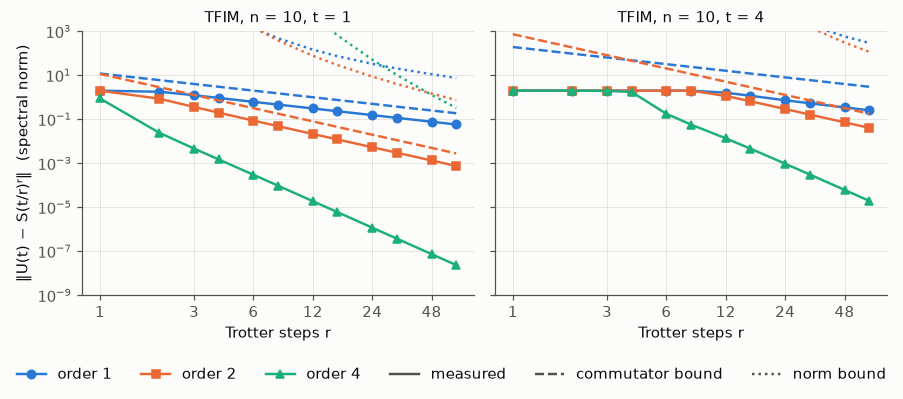

In [4]:
plots.bounds_vs_measured(noiseless, "tfim", 10, [1.0, 4.0], save=FIG / "fig1_bounds.png");

The measured errors fall as $r^{-1}$, $r^{-2}$ and $r^{-4}$ at t = 1. At t = 4 the steps are too coarse at small r:
the error saturates at its maximum of 2 until the formula enters its asymptotic regime. The ratio of each bound to the
measured error, median over r ≥ 16:

commutator      norm
model order                     
tfim  1           6.48       215
      2           4.03       816
      4            nan  1.17e+07
xxz   1           7.19       281
      2           3.84       808
      4            nan   1.3e+07

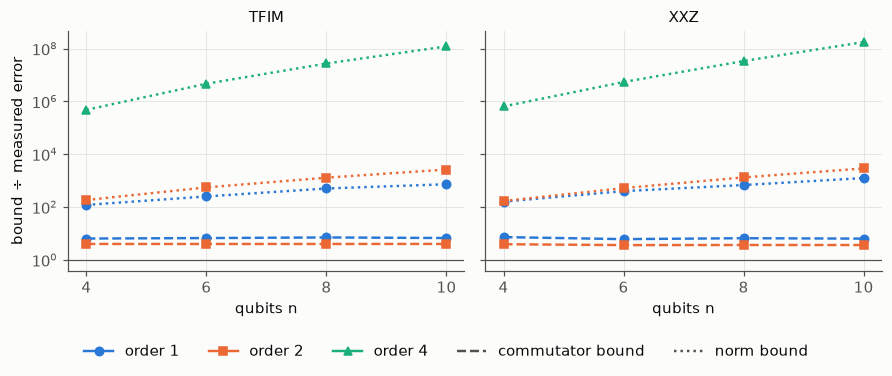

In [5]:
plots.bound_looseness(noiseless, save=FIG / "fig1b_looseness.png");
d = noiseless[(noiseless.r >= 16) & noiseless.spectral_err.notna()]
looseness = (d.assign(commutator=d.commutator_bound / d.spectral_err, norm=d.norm_bound / d.spectral_err)
               .groupby(["model", "order"])[["commutator", "norm"]].median())
looseness.map("{:.3g}".format)

The commutator bound stays within a constant factor of the truth (about 6–7× at first order, 4× at second) at every
chain length, because both it and the true error grow linearly with n. The norm bound grows like $n^{p+1}$ while the
true error grows like $n$, so its overestimate climbs with chain length, to 10³ at order 2 and 10⁸ at order 4 for
10 qubits. These reproduce Childs et al.'s conclusions on a different pair of models.

Worst-case bounds are what the analytic r\* formulas are built from, which matters in the next section.

## 3. Question 2: the optimal step count under device noise

Each TFIM circuit is transpiled onto `FakeTorino` and simulated as a density matrix with Qiskit Aer, using the
backend's calibrated noise: depolarizing and thermal-relaxation errors on every gate, separate one- and two-qubit rates,
and relaxation on idle qubits. Readout error is left out (on hardware it would be mitigated separately). The main
metric is the trace distance between the noisy output and the exact state $e^{-iHt}|\psi_0\rangle$.

The noise per Trotter step, from the calibration: the slope of the summed gate error of the transpiled circuit
against r. (Median CZ error on this snapshot is 4.2 × 10⁻³; single-qubit gates are about 15× better.)

In [6]:
summary = predict.summarize(noisy, noiseless)
(summary[summary.t == 1.0].pivot(index="n", columns="order", values=["twoq_per_step", "p_step"])
   .map("{:.3g}".format))

twoq_per_step           p_step               
order             1   2    4       1       2      4
n                                                  
4                 6   6   30  0.0238  0.0238  0.119
6                10  10   50  0.0387  0.0387  0.193
8                14  14   70  0.0859  0.0858   0.43
10               18  18   90  0.0751  0.0751  0.373
12               22  22  110   0.123   0.123  0.614

Orders 1 and 2 cost the same per step (the grouping at work); order 4 costs 5×. The per-step error is not monotonic in
n: the 8-qubit chain landed on noisier qubits than the 10-qubit one.

The trade-off at 8 qubits, for three evolution times. Solid lines include device noise; dashed lines are the noiseless
Trotter error of the same circuits; rings mark the measured optimum.

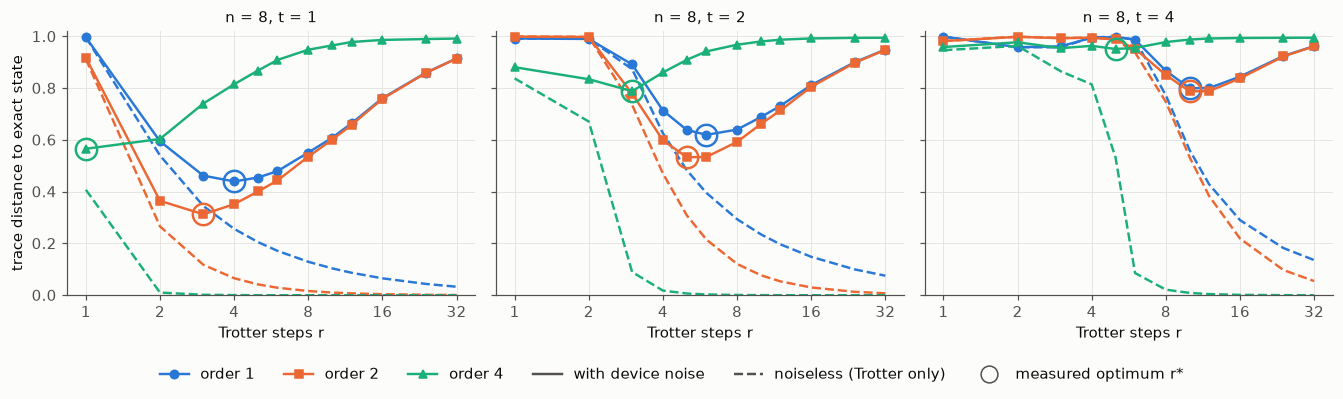

In [7]:
plots.noisy_tradeoff(noisy, 8, [1.0, 2.0, 4.0], save=FIG / "fig2_noisy_tradeoff.png");

The optimum moves to larger r as t grows, as both theories predict ($r^* \propto t$ at fixed hardware). The errors at
the optimum are large: at t = 4 even the best circuit sits at trace distance 0.8 from the target, and at 10–12 qubits
the best first- and second-order circuits reach only 0.77–0.90.

Measured r\* for every chain length, time and order:

In [8]:
summary.pivot(index="n", columns=["t", "order"], values="r_measured").astype(int)

t     1.0       2.0       4.0       
order   1  2  4   1  2  4   1   2  4
n                                   
4       6  4  2   8  6  3  16  12  5
6       5  3  2   8  6  3  12  12  6
8       4  3  1   6  5  3  10  10  5
10      4  3  2   6  6  3  12  12  6
12      4  3  1   6  5  3  12  12  6

Not every optimum is sharp. `min_rise` is how far the error climbs above its minimum on the flatter side of r\*; we
call a minimum clear when it climbs by at least 0.05 in trace distance on both sides. The exceptions:

In [9]:
clear = summary.min_rise >= 0.05
print(f"clear minima: {clear.sum()} of {len(summary)}")
summary.loc[~clear, ["n", "t", "order", "r_measured", "err_at_optimum", "min_rise"]]

clear minima: 42 of 45


,n,t,order,r_measured,err_at_optimum,min_rise
26,8,4.0,4,5,0.952,0.026
29,10,1.0,4,2,0.564,0.020
44,12,4.0,4,6,0.988,0.010


All 30 first- and second-order minima are clear; three fourth-order ones fall short. The shallowest, the 12-qubit chain
at t = 4, is flat: its state is close to maximally mixed (trace distance 0.99) for every r, so its r\* means nothing.

### Predicted against measured

Both papers minimize $a/r^q + b\,r$, giving $r^* = (q\,a/b)^{1/(q+1)}$. We feed each its own Trotter constant $a$
and take $b$ from the calibration above:

* **Knee & Munro**, first order with depolarizing noise $p$ per step, in diamond norm:
  $D(r) \approx (1-p)\,\mathscr{A}\,t^2/(2r) + 2pr$, where $\mathscr{A}$ is the diamond norm of
  $\rho \mapsto [\,[A,B],\rho\,]$, the spectral spread of $i[A,B]$. They also write the general form
  $D \le \mathscr{C}/r^{s-1} + \mathscr{D}r$ for higher orders but evaluate it only at first order. Our second-order
  version takes $\mathscr{C}$ from Childs et al.'s second-order commutator bound, so its numbers are our extension, not
  theirs.
* **Avtandilyan & Pogosov**, TFIM with explicit constants: $a = t^2 Jh(n-1)$ at first order and
  $a = 4t^3Jh(J+h)(n-1)$ at second. Their estimates are order-of-magnitude (written with "∼"); we use them as published.
* **Xu, Zhao, Fan & Zhao** ([arXiv:2504.10247](https://arxiv.org/abs/2504.10247)) keep a worst-case constant (the
  nested commutator norm: $\|[A,B]\|/2$ at first order, Childs et al.'s at second) but let each step's error decay as
  the noise contracts the state toward the maximally mixed one: they minimize
  $\sum_{d=1}^{r} \big(p + B_p (t/r)^{q+1}\big)\, e^{-\gamma d/2}$ (their Eq. 14). We use the calibrated per-step error
  for $p$ and $\gamma = p/n$ for the per-qubit rate. Without the decay this is their closed form (Eq. 15), the same
  power law as Knee & Munro with the same constant.
* **Semi-empirical (this work):** keep the calibrated per-step error $p$, but replace the analytic Trotter term with the
  actual noiseless Trotter error $E_T(r)$ of the initial state, and treat the two as independent failures:
  minimize $1 - (1 - E_T(r))\,e^{-pr}$. No noisy simulation is needed.

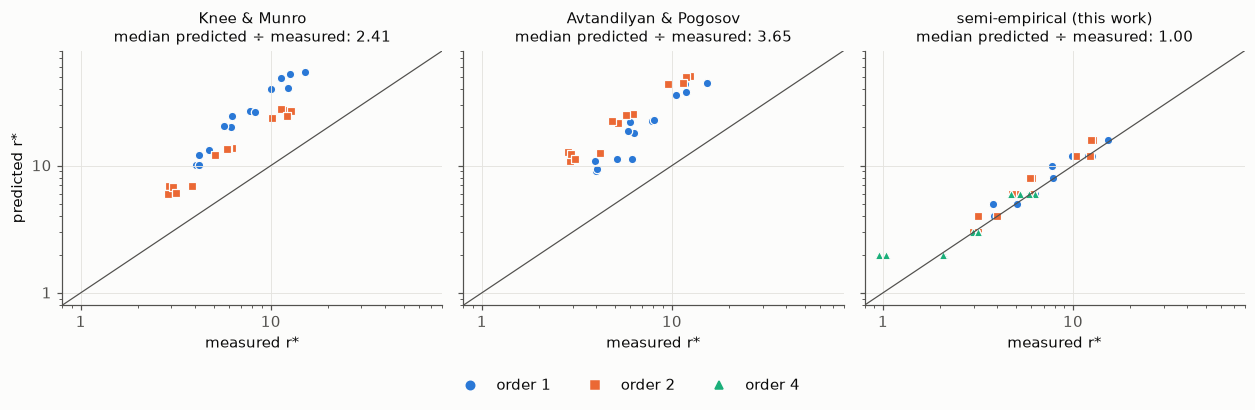

In [10]:
plots.predicted_vs_measured(summary, save=FIG / "fig3_predictions.png");

In [11]:
low = summary[summary.order <= 2]
ratio = lambda col: low[col] / low.r_measured
table = pd.DataFrame({
    "Knee & Munro": ratio("r_knee_munro").groupby(low.order).median(),
    "Avtandilyan & Pogosov": ratio("r_avtandilyan_pogosov").groupby(low.order).median(),
    "Xu et al.": ratio("r_xu_et_al").groupby(low.order).median(),
    "semi-empirical": ratio("r_semi_empirical").groupby(low.order).median(),
})
table.index.name = "order"
print("Median predicted r* / measured r*")
display(table.round(2))

# Per-step error that would make each analytic formula exact: b scales as (predicted/measured)^(q+1), q = order.
mult = pd.DataFrame({name: (ratio(col) ** (low.order + 1)).groupby(low.order).median()
                     for name, col in [("Knee & Munro", "r_knee_munro"),
                                       ("Avtandilyan & Pogosov", "r_avtandilyan_pogosov")]})
mult.index.name = "order"
print("Per-step error needed for an exact prediction, as a multiple of the calibrated one")
display(mult.round(1))

grid = np.sort(noisy.r.unique())
snap = lambda r: grid[np.abs(np.log(grid) - np.log(r)).argmin()]   # nearest grid point, for continuous r*
step_apart = lambda a, b: abs(np.searchsorted(grid, snap(a)) - np.searchsorted(grid, snap(b))) <= 1
hit = summary.apply(lambda s: step_apart(s.r_semi_empirical, s.r_measured), axis=1)
print("Xu et al. / Knee & Munro r*: median", round((summary.r_xu_et_al / summary.r_knee_munro).median(), 3),
      "largest", round((summary.r_xu_et_al / summary.r_knee_munro).max(), 3))
print("Semi-empirical r* within one grid step of measured:", hit.groupby(summary.order).mean().map("{:.0%}".format).to_dict())
print(f"... in {hit[clear].sum()} of {clear.sum()} clear minima")

Median predicted r* / measured r*


,Knee & Munro,Avtandilyan & Pogosov,Xu et al.,semi-empirical
order,,,,
1,3.38,2.84,3.71,1.0
2,2.30,4.21,2.32,1.2


Per-step error needed for an exact prediction, as a multiple of the calibrated one


,Knee & Munro,Avtandilyan & Pogosov
order,,
1,11.4,8.1
2,12.1,74.7


Xu et al. / Knee & Munro r*: median 1.033 largest 1.207
Semi-empirical r* within one grid step of measured: {1: '100%', 2: '100%', 4: '100%'}
... in 42 of 42 clear minima


The analytic formulas get the scaling right and the level wrong, always on the high side. Xu et al.'s refinement moves
r\* the wrong way: its decay makes late steps cheaper, so its r\* is Knee & Munro's or slightly larger (3% at the
median, 20% at most), and the overshoot stays. The semi-empirical
predictor changes two things at once, though: the Trotter term (the state's actual error instead of a worst-case
constant) and how the two errors combine (saturating instead of additive). That saturation alone could move r\*,
since the errors at the optimum are large. To separate them, cross three Trotter terms with both rules:

* Trotter term: Knee & Munro's $a/r^q$; this state's $C/r^q$, with $C$ fitted to its noiseless error (the analytic
  formulas' own power-law form); or the noiseless error $E_T(r)$ itself.
* Rule: additive, $\text{term} + p\,r$ as in both papers; or saturating, $1 - (1 - \text{term})\,e^{-pr}$.

In [12]:
ab = predict.ablation(noisy, noiseless)
low_ab = ab[ab.order <= 2]
rows = {}
for term in ("knee_munro", "fitted", "E_T"):
    for rule in ("additive", "saturating"):
        col = f"{term} {rule}"
        ratio = (low_ab[col] / low_ab.r_measured).groupby(low_ab.order).median()
        hits = sum(step_apart(a, b) for a, b in zip(low_ab[col], low_ab.r_measured))
        rows[(term, rule)] = {"median ratio, order 1": ratio[1], "median ratio, order 2": ratio[2],
                              "within one step": f"{hits}/{len(low_ab)}"}
display(pd.DataFrame(rows).T.round(2))
excess = (low_ab.a_knee_munro / low_ab.c_fitted).groupby(low_ab.order)
print("Knee & Munro's constant / this state's fitted constant: median",
      excess.median().round(1).to_dict(), "minimum", excess.min().round(1).to_dict())

median ratio, order 1 median ratio, order 2  \
knee_munro additive                   3.382                 2.297   
           saturating                  6.21                 2.547   
fitted     additive                   0.869                 1.089   
           saturating                 1.015                 1.192   
E_T        additive                     1.0                   1.0   
           saturating                   1.0                   1.2   

                      within one step  
knee_munro additive              0/30  
           saturating            0/30  
fitted     additive             28/30  
           saturating           30/30  
E_T        additive             23/30  
           saturating           30/30

Knee & Munro's constant / this state's fitted constant: median {1: 14.6, 2: 9.3} minimum {1: 6.1, 2: 6.4}


The overshoot comes from the Trotter term. Knee & Munro's constant exceeds the state's fitted one by a median 15× at
first order and 9× at second, never less than 6×: partly the worst-case looseness of section 2, partly the gap between
the worst input state and this one. Since $r^* \propto a^{1/(q+1)}$, that alone predicts overshoots of about
$15^{1/2} \approx 3.9$ and $9^{1/3} \approx 2.1$, close to the measured 3.4 and 2.3. Swapping only the constant, inside
the additive formula, removes the overshoot (median ratio 0.87 and 1.09, 28 of 30 within one step). Swapping only the
rule does not (6.2 and 2.6, none within one step). The saturating rule earns the last two hits: it matters where the
errors at the optimum are large, as they are here.

Answering question 2 as posed: Knee & Munro's prediction becomes accurate if the effective error per step is set about
11–12× above the calibrated value. That number is not a property of the hardware, though; it absorbs the looseness of the
Trotter term, so it would change with the initial state and the evolution time.

### Which order to use

Lowest trace distance reached by each order, at its own optimum:

In [13]:
best = summary.pivot(index=["n", "t"], columns="order", values="err_at_optimum")
best["best order"] = best.idxmin(axis=1)
best.round(3)

order       1      2      4  best order
n  t                                   
4  1.0  0.199  0.119  0.232           2
   2.0  0.295  0.223  0.359           2
   4.0  0.439  0.401  0.558           2
6  1.0  0.281  0.178  0.347           2
   2.0  0.410  0.324  0.511           2
   4.0  0.571  0.557  0.768           2
8  1.0  0.440  0.313  0.566           2
   2.0  0.620  0.533  0.789           2
   4.0  0.800  0.788  0.952           2
10 1.0  0.433  0.292  0.564           2
   2.0  0.602  0.506  0.754           2
   4.0  0.786  0.766  0.943           2
12 1.0  0.558  0.420  0.697           2
   2.0  0.732  0.661  0.891           2
   4.0  0.901  0.890  0.988           2

Second order wins at every size and time. Its equal cost is the textbook Strang-splitting saving from section 1 (two
groups, merged half-steps), not a new trick. What it changes is a published conclusion: Avtandilyan & Pogosov find
first order optimal at error rates like these because their cost model charges the second-order formula twice the
gates of the first. With the merge it costs the same, so it is a free improvement. Fourth order needs 5× the gates and
loses everywhere at these error rates; section 5 measures how much better the device has to be before it wins.

### A caution on single observables

Errors in one observable are a poor way to locate r\*. Trotter error has a sign, noise mostly shrinks expectation values
toward zero, and the two can cancel. The minima of single-observable errors scatter where the trace distance does not:

In [14]:
obs_cols = {"trace_dist": "trace distance", "mz_err": "<M_z> error", "mx_err": "<M_x> error", "zz_mid_err": "<ZZ> error"}
rstar = {label: noisy.loc[noisy.groupby(["n", "t", "order"])[col].idxmin()].set_index(["n", "t", "order"]).r
         for col, label in obs_cols.items()}
pd.DataFrame(rstar).astype(int).xs(2, level="order").T

n               4           6           8           10          12        
t              1.0 2.0 4.0 1.0 2.0 4.0 1.0 2.0 4.0 1.0 2.0 4.0 1.0 2.0 4.0
trace distance   4   6  12   3   6  12   3   5  10   3   6  12   3   5  12
<M_z> error      6  32  12   5  12   8   5  12   5   5  16   4   5  10   4
<M_x> error      3   8   8   2   4  16   2   4   8   2   5   8   2   5   8
<ZZ> error       1   5   6   3   1  12   2   2   2   3   5   8   2   4   3

For second order, the trace-distance optimum grows steadily with t (3–4, then 5–6, then 10–12). The magnetization's
optimum instead jumps to 10–32 at t = 2 and falls back to 4–5 at t = 4, and the mid-chain ZZ correlator's wanders between
1 and 12 with no pattern. On hardware, where only observables are available, several
of them (or an observable with a known noise response) are needed to place r\* reliably.

## 4. Question 3: the same trade-off on an IBM device

The Open plan offers Heron r2 devices (not Torino), so the check compares one device with *its own* noise model, built
from its calibration at submission time. One TFIM chain, n = 12 and t = 2, first and second order at nine values of r:
18 circuits in one Estimator job, 8192 shots each, readout-error mitigation (TREX) only, so gate noise stays visible.

Hardware gives expectation values, not states, so the metric is the RMS error over all 46 local Paulis
($Z_i$, $X_i$, $Z_iZ_{i+1}$, $X_iX_{i+1}$), measured in two bases. Squaring each error before averaging stops errors
in different observables from cancelling. Shot noise inflates a mean squared error by the mean variance, so the
device's RMS has that bias subtracted, and its error bars come from a parametric bootstrap.

ibm_kingston, job dbgl02kdgr2s73crnm6g, chain on qubits [128, 129, 118, 109, 108, 107, 97, 87, 88, 89, 90, 91], device time 92 s


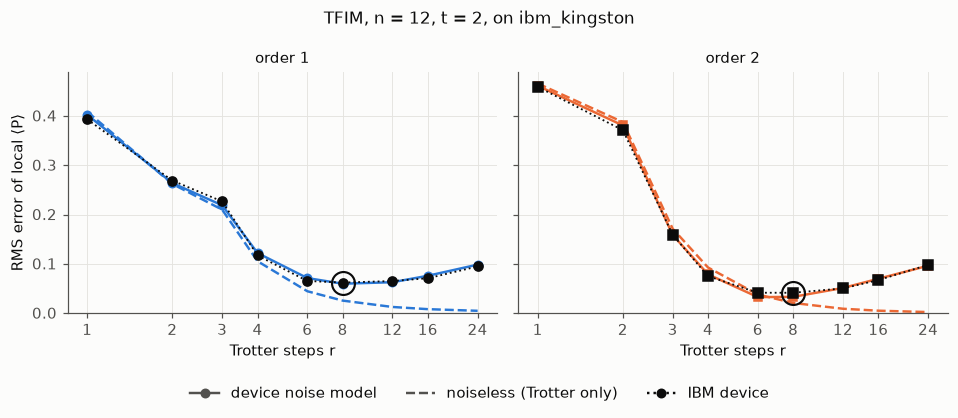

In [15]:
import json
from qtrotter.hardware import rms_table

hw_job = json.load(open(ROOT / "results/hardware_job.json"))
hw_circuits = pd.read_csv(ROOT / "results/hardware_circuits.csv")
hw = rms_table(pd.read_csv(ROOT / "results/hardware_values.csv"))
cfg_hw = hw_job["config"]
print(f"{hw_job['backend']}, job {hw_job['job_id']}, chain on qubits {hw_job['layout']}, "
      f"device time {hw_job['usage_seconds']:.0f} s")
plots.hardware_comparison(hw, title=f"TFIM, n = {cfg_hw['n']}, t = {cfg_hw['t']:g}, on {hw_job['backend']}",
                          save=FIG / "fig4_hardware.png");

In [16]:
table = hw.pivot(index="r", columns=["source", "order"], values="rms")
device = hw[hw.source == "hardware"].set_index(["order", "r"]).rms_std
for order in (1, 2):
    table[("device ±", order)] = device.xs(order)
table.round(3)

source hardware        noise_model        trotter        device ±       
order         1      2           1      2       1      2        1      2
r                                                                       
1         0.393  0.459       0.402  0.461   0.409  0.466    0.001  0.002
2         0.269  0.371       0.264  0.381   0.262  0.387    0.002  0.002
3         0.227  0.159       0.219  0.159   0.210  0.171    0.002  0.002
4         0.117  0.075       0.122  0.079   0.105  0.093    0.002  0.002
6         0.065  0.041       0.071  0.033   0.044  0.038    0.002  0.002
8         0.062  0.041       0.060  0.033   0.025  0.021    0.002  0.002
12        0.065  0.050       0.063  0.051   0.013  0.009    0.002  0.002
16        0.071  0.067       0.076  0.070   0.008  0.005    0.002  0.002
24        0.095  0.098       0.098  0.096   0.005  0.002    0.002  0.002

In [17]:
norms12 = noiseless[(noiseless.model == "tfim") & (noiseless.n == cfg_hw["n"])].iloc[0]
rows = []
for order, g in hw_circuits.groupby("order"):
    p_step = predict.per_step_error(g.r, g.gate_error_sum)
    opt = lambda src: hw[(hw.source == src) & (hw.order == order)].set_index("r").rms
    rows.append({"order": order, "per-step error": p_step,
                 "device r*": opt("hardware").idxmin(), "noise model r*": opt("noise_model").idxmin(),
                 "device error at r*": opt("hardware").min(), "model error at r*": opt("noise_model").min(),
                 "Knee & Munro r*": predict.knee_munro(order, cfg_hw["t"], p_step, norms12),
                 "Avtandilyan & Pogosov r*": predict.avtandilyan_pogosov(order, cfg_hw["t"], p_step, cfg_hw["n"])})
pd.DataFrame(rows).set_index("order").round(3)

,per-step error,device r*,noise model r*,device error at r*,model error at r*,Knee & Munro r*,Avtandilyan & Pogosov r*
order,,,,,,,
1,0.047,8,8,0.062,0.060,34.216,30.439
2,0.047,8,6,0.041,0.033,16.797,30.957


The device lands where its noise model says it will. Both optima match (r\* = 8 at first order; at second order r = 6
and 8 tie on the device, 0.041 each), and the device's error stays within 0.01 of the model at every r. The model is
slightly optimistic only near the second-order optimum (0.041 measured against 0.033 predicted, about four standard
errors). The proposal expected the hardware optimum to fall below the simulated one, since IBM notes that Aer noise
models are usually milder than the device; for these circuits on `ibm_kingston` that did not happen.

The analytic formulas overshoot here too, and second order again reaches about two thirds of first order's error at the
same gate count.

### The semi-empirical predictor on hardware

In section 3 the per-step error p comes from the same noise model that generated the data, so this run is the
predictor's only independent test. Hardware gives observables, not states, so the predictor needs an observable
version. The global-depolarizing assumption behind $1 - (1 - E_T)\,e^{-pr}$ says every traceless observable shrinks by
$e^{-pr}$: predict each value as $e^{-pr}\langle O\rangle_\mathrm{Trotter}$ and minimize the RMS error against exact
evolution. The last two columns check that assumption: the least-squares factor by which the measured values are a
shrunken copy of the noiseless Trotter values.

In [18]:
hw_values = pd.read_csv(ROOT / "results/hardware_values.csv")
exact_hw = hw_values[hw_values.source == "exact"].set_index("observable").value
values_of = lambda source, order, r: (hw_values[(hw_values.source == source) & (hw_values.order == order)
                                                & (hw_values.r == r)].set_index("observable").value.loc[exact_hw.index])
rows = []
for order, g in hw_circuits.groupby("order"):
    p_step = predict.per_step_error(g.r, g.gate_error_sum)
    for r in sorted(g.r):
        trotter = values_of("trotter", order, r)
        shrink = lambda source: float(values_of(source, order, r) @ trotter / (trotter @ trotter))
        rows.append({"order": order, "r": r, "predicted rms": predict.damped_rms(trotter, exact_hw, p_step, r),
                     "exp(-pr)": np.exp(-p_step * r),
                     "shrink, noise model": shrink("noise_model"), "shrink, device": shrink("hardware")})
pred_hw = pd.DataFrame(rows).set_index(["order", "r"])
pred_hw.insert(1, "device rms", hw[hw.source == "hardware"].set_index(["order", "r"]).rms)
for order in (1, 2):
    o = pred_hw.xs(order)
    r_hat = o["predicted rms"].idxmin()
    print(f"order {order}: predicted r* = {r_hat}; device error there {o['device rms'][r_hat]:.3f}, "
          f"at the device's optimum {o['device rms'].min():.3f}")
pred_hw.round(3)

order 1: predicted r* = 6; device error there 0.065, at the device's optimum 0.062
order 2: predicted r* = 4; device error there 0.075, at the device's optimum 0.041


predicted rms  device rms  exp(-pr)  shrink, noise model  \
order r                                                              
1     1           0.394       0.393     0.954                0.974   
      2           0.262       0.269     0.909                0.966   
      3           0.229       0.227     0.867                0.937   
      4           0.147       0.117     0.827                0.932   
      6           0.119       0.065     0.752                0.911   
      8           0.128       0.062     0.684                0.893   
      12          0.160       0.065     0.566                0.850   
      16          0.192       0.071     0.468                0.803   
      24          0.243       0.095     0.320                0.733   
2     1           0.457       0.459     0.954                0.970   
      2           0.375       0.371     0.909                0.938   
      3           0.149       0.159     0.867                0.935   
      4           0.074       0.075     0.827                0.930   
      6           0.076       0.041     0.752                0.909   
      8           0.105       0.041     0.684                0.891   
      12          0.152       0.050     0.566                0.848   
      16          0.188       0.067     0.468                0.801   
      24          0.242       0.098     0.320                0.732   

          shrink, device  
order r                   
1     1            0.937  
      2            0.921  
      3            0.886  
      4            0.941  
      6            0.942  
      8            0.933  
      12           0.904  
      16           0.901  
      24           0.879  
2     1            0.939  
      2            0.870  
      3            0.935  
      4            0.918  
      6            0.946  
      8            0.930  
      12           0.924  
      16           0.910  
      24           0.887

The predictor comes out one grid step low at both orders. At first order it picks r = 6 against the device's 8, which
costs little (0.065 against 0.062). At second order it picks r = 4 against 6–8, which nearly doubles the error (0.075
against 0.041), although its own curve is nearly level between 4 and 6. This time the noise side is off: the local Paulis shrink by about 0.9 at r = 8, on the device and in
its noise model alike, not by $e^{-pr} = 0.68$. Noise damps a local observable only through errors that fail to commute
with it after back-propagation, while the whole state's fidelity drops at any error, so global damping overstates the
noise on observables and pulls r\* down. An observable version needs a local noise rate. Even so, it lands much closer
than the analytic formulas, which predict 17 to 34.

## 5. Follow-ups: a second model, and better devices

Two checks beyond the three questions, both on noise models only and both run on the CPU: the XXZ chain under noise
(so far it served only the bound comparison), and the TFIM on uniformly better devices, which tests the claim that
higher orders pay off once gate errors drop by about an order of magnitude.

A helper for the grid-step comparisons below (the same criterion as in section 3):

In [19]:
def within_one_step(predicted, measured, grid):
    grid = np.log(np.asarray(grid, float))
    nearest = lambda r: np.abs(grid - np.log(r)).argmin()
    return abs(nearest(predicted) - nearest(measured)) <= 1


def ablation_table(ab, grid):
    low = ab[ab.order <= 2]
    rows = {}
    for term in ("knee_munro", "fitted", "E_T"):
        for rule in ("additive", "saturating"):
            col = f"{term} {rule}"
            ratio = (low[col] / low.r_measured).groupby(low.order).median()
            hits = sum(within_one_step(a, b, grid) for a, b in zip(low[col], low.r_measured))
            rows[(term, rule)] = {"median ratio, order 1": ratio[1], "median ratio, order 2": ratio[2],
                                  "within one step": f"{hits}/{len(low)}"}
    return pd.DataFrame(rows).T.round(2)

### The XXZ chain under noise

The same pipeline on the XXZ chain ($\Delta = 0.5$, from the Néel state $|0101\ldots\rangle$, 4 to 10 qubits). Its two
groups, even and odd bonds, merge at second order just as the TFIM's do, and the transpiler compiles each bond's
$XX + YY + \Delta ZZ$ block to three CZ gates. Avtandilyan & Pogosov give constants only for the TFIM, so only Knee &
Munro and the semi-empirical predictor are compared.

In [20]:
noisy_xxz = pd.read_csv(ROOT / "results/noisy_xxz.csv")
sx = predict.summarize(noisy_xxz, noiseless)
grid_x = sorted(noisy_xxz.r.unique())
sx["clear"] = sx.min_rise >= 0.05
sx["hit"] = [within_one_step(p, m, grid_x) for p, m in zip(sx.r_semi_empirical, sx.r_measured)]
low_x = sx[sx.order <= 2]
print(f"clear minima: {sx.clear.sum()} of {len(sx)} ({low_x.clear.sum()} of {len(low_x)} at orders 1-2)")
print(f"semi-empirical within one grid step: {sx.hit[sx.clear].sum()} of the clear minima, {sx.hit.sum()} of all")
print("Knee & Munro, median predicted / measured r*:",
      (low_x.r_knee_munro / low_x.r_measured).groupby(low_x.order).median().round(2).to_dict())
best_x = sx.pivot(index=["n", "t"], columns="order", values="err_at_optimum")
print("best order at every (n, t):", sorted(int(o) for o in best_x.idxmin(axis=1).unique()))
sx.pivot(index="n", columns=["t", "order"], values="r_measured").astype(int)

clear minima: 31 of 36 (24 of 24 at orders 1-2)
semi-empirical within one grid step: 30 of the clear minima, 35 of all
Knee & Munro, median predicted / measured r*: {1: 2.86, 2: 2.42}
best order at every (n, t): [2]


t     1.0       2.0       4.0       
order   1  2  4   1  2  4   1   2  4
n                                   
4       5  3  1   8  6  2  16  12  4
6       6  3  2   8  6  3  16  12  4
8       5  3  2   8  6  2  16  12  5
10      5  3  2   8  6  3  16  12  4

In [21]:
ab_x = predict.ablation(noisy_xxz, noiseless)
display(ablation_table(ab_x, grid_x))
low_ab_x = ab_x[ab_x.order <= 2]
print("Knee & Munro's constant / this state's fitted constant: median",
      (low_ab_x.a_knee_munro / low_ab_x.c_fitted).groupby(low_ab_x.order).median().round(1).to_dict())
sx.loc[sx.clear & ~sx.hit, ["n", "t", "order", "r_measured", "r_semi_empirical", "min_rise"]]

median ratio, order 1 median ratio, order 2  \
knee_munro additive                   2.858                 2.416   
           saturating                 5.794                 2.724   
fitted     additive                   0.841                 1.159   
           saturating                 1.031                 1.249   
E_T        additive                   0.775                 1.333   
           saturating                   1.0                 1.333   

                      within one step  
knee_munro additive              0/24  
           saturating            0/24  
fitted     additive             21/24  
           saturating           24/24  
E_T        additive             16/24  
           saturating           24/24

Knee & Munro's constant / this state's fitted constant: median {1: 12.4, 2: 9.1}


,n,t,order,r_measured,r_semi_empirical,min_rise
17,6,4.0,4,4,6.0,0.134


Everything carries over to the second model. All 24 first- and second-order minima are clear; the five shallow ones
are fourth order. The semi-empirical predictor lands within one grid step in 30 of the 31 clear configurations; the miss
is n = 6, t = 4, fourth order (6 against 4). It does run one grid step high at second order and t = 4 (16 against 12, at
every n). Knee & Munro overshoot by a median 2.9× at first order and 2.4× at second, and the ablation names the same
cause as for the TFIM: their constant is 12× and 9× the state's fitted one, and swapping in the fitted one removes the
overshoot (21 of 24 within one step with their additive rule, 24 of 24 with the saturating one), while changing only the
rule does not. Second order wins at every size and time, fourth order loses everywhere, and at t = 4 the best 10-qubit
circuit is again far from its target (trace distance 0.91).

### Better devices: when does fourth order pay off?

Avtandilyan & Pogosov conclude that higher orders become advantageous once gate errors drop by "approximately an order
of magnitude"; for the Ising model they place the switch from first to second order near a per-gate error of
$P_0' \approx 10^{-4}$. Here every calibrated error rate of Torino is multiplied by a scale from 1 down to 0.01: gate
errors times the scale, $T_1$ and $T_2$ divided by it (`qtrotter.noisy.scaled_backend`). The circuits do not change,
only the noise. TFIM, n = 10, the same three times and orders, with r up to 192. In the figure, dotted lines mark their
two thresholds: a tenfold improvement, and $P_0' = 10^{-4}$ per exponential (their first-to-second-order switch).

Before the sweep ran, the semi-empirical predictor was asked for r\* and the error at r\* at every scale, using only the
noiseless Trotter error and the scaled per-step error from question 2 (`scripts/predict_noise_scaling.py`, saved as
`results/noise_scaling_predicted.csv`). The simulations below test those predictions.

In [22]:
scaling = pd.read_csv(ROOT / "results/noise_scaling.csv")
predicted = pd.read_csv(ROOT / "results/noise_scaling_predicted.csv")
by_scale = pd.concat([predict.summarize(g, noiseless).assign(noise_scale=s)
                      for s, g in scaling.groupby("noise_scale")], ignore_index=True)
by_scale = by_scale.merge(predicted[["t", "order", "noise_scale", "r_predicted", "err_predicted"]],
                          on=["t", "order", "noise_scale"])

# Scale 1 repeats question 2 at n = 10 (there on the GPU, here on the CPU).
same = scaling[scaling.noise_scale == 1].merge(noisy[noisy.n == 10], on=["model", "n", "t", "order", "r"])
print(f"scale 1 against question 2: {len(same)} shared circuits, largest trace-distance difference "
      f"{(same.trace_dist_x - same.trace_dist_y).abs().max():.0e}")

# Avtandilyan & Pogosov's per-gate error: the per-step error over K = 2n - 1 exponentials.
p0 = by_scale[(by_scale.noise_scale == 1) & (by_scale.order == 1)].p_step.mean() / (2 * 10 - 1)
print(f"per-exponential error at scale 1: {p0:.1e}; their P0' = 1e-4 sits at scale {1e-4 / p0:.3f}")

scale 1 against question 2: 108 shared circuits, largest trace-distance difference 9e-16
per-exponential error at scale 1: 4.0e-03; their P0' = 1e-4 sits at scale 0.025


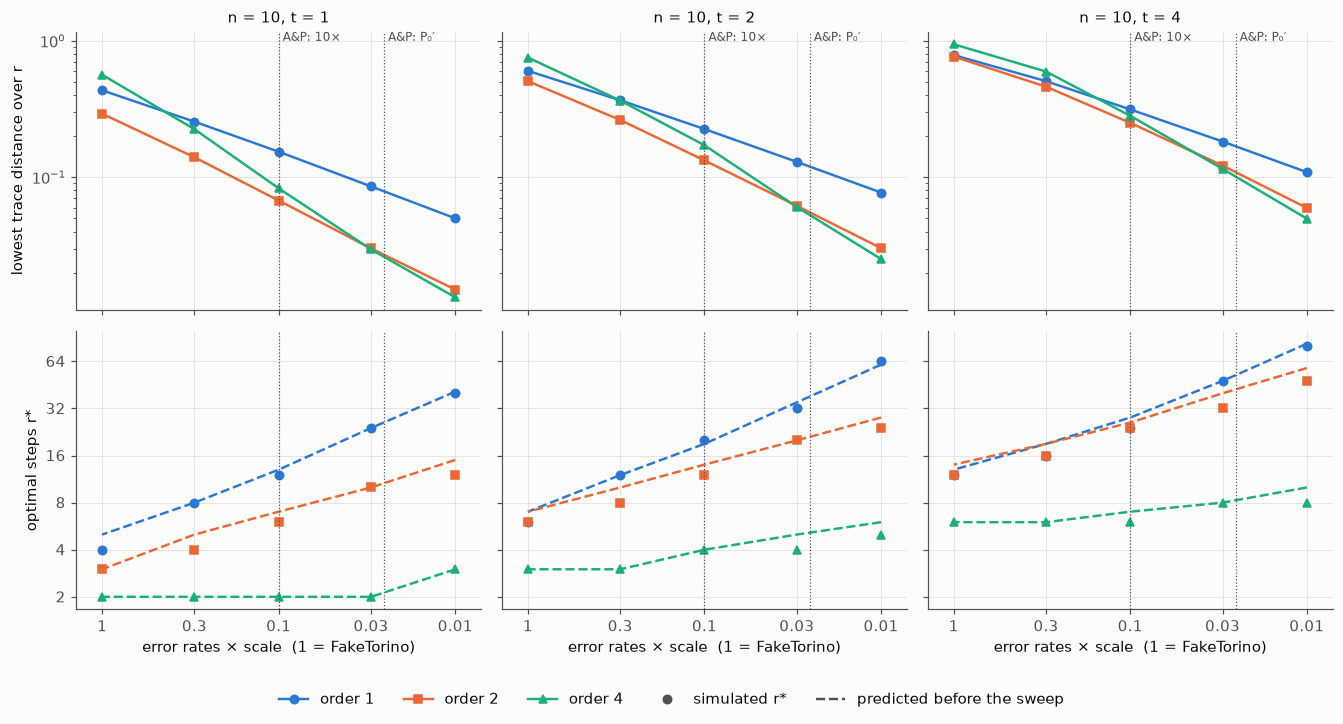

In [23]:
plots.noise_scaling(by_scale, predicted, [1.0, 2.0, 4.0],
                    thresholds=[(0.1, "A&P: 10×"), (1e-4 / p0, "A&P: P₀′")],
                    save=FIG / "fig5_noise_scaling.png");

In [24]:
best_s = (by_scale.pivot_table(index=["t", "noise_scale"], columns="order", values="err_at_optimum")
          .sort_index(ascending=[True, False]))
best_s["best order"] = best_s.idxmin(axis=1)
best_s["predicted best"] = (by_scale.pivot_table(index=["t", "noise_scale"], columns="order", values="err_predicted")
                            .sort_index(ascending=[True, False]).idxmin(axis=1))


def crossover(g):
    # Scale at which order 4 catches order 2, interpolating log(err4 / err2) in log(scale).
    s, d = np.log(g.index.to_numpy(float)), np.log((g[4] / g[2]).to_numpy())
    i = np.where(np.sign(d[:-1]) != np.sign(d[1:]))[0]
    return np.exp(s[i[0]] - d[i[0]] * (s[i[0] + 1] - s[i[0]]) / (d[i[0] + 1] - d[i[0]])) if len(i) else np.nan


for t, g in best_s.groupby(level="t"):
    print(f"t = {t:g}: order 4 catches order 2 at scale {crossover(g.droplevel('t')):.3f}")
best_s.round(4)

t = 1: order 4 catches order 2 at scale 0.033
t = 2: order 4 catches order 2 at scale 0.033
t = 4: order 4 catches order 2 at scale 0.044


order                1      2      4  best order  predicted best
t   noise_scale                                                 
1.0 1.00         0.433  0.292  0.564           2               2
    0.30         0.255  0.140  0.225           2               2
    0.10         0.154  0.068  0.083           2               2
    0.03         0.086  0.030  0.030           4               2
    0.01         0.050  0.015  0.013           4               4
2.0 1.00         0.602  0.506  0.754           2               2
    0.30         0.366  0.263  0.365           2               2
    0.10         0.226  0.133  0.172           2               2
    0.03         0.130  0.062  0.061           4               4
    0.01         0.077  0.030  0.025           4               4
4.0 1.00         0.786  0.766  0.943           2               2
    0.30         0.506  0.461  0.595           2               2
    0.10         0.314  0.250  0.282           2               2
    0.03         0.183  0.122  0.115           4               4
    0.01         0.109  0.060  0.050           4               4

In [25]:
grid_s = sorted(scaling.r.unique())
by_scale["clear"] = by_scale.min_rise >= 0.05
by_scale["hit"] = [within_one_step(p, m, grid_s) for p, m in zip(by_scale.r_predicted, by_scale.r_measured)]
print(f"clear minima: {by_scale.clear.sum()} of {len(by_scale)}; predicted before the sweep and within one grid "
      f"step: {by_scale.hit[by_scale.clear].sum()} of the clear ones, {by_scale.hit.sum()} of all")
low_s = by_scale[by_scale.order <= 2]
ratios = pd.DataFrame({name: (low_s[col] / low_s.r_measured).groupby([low_s.order, low_s.noise_scale]).median()
                       for col, name in [("r_knee_munro", "Knee & Munro"),
                                         ("r_avtandilyan_pogosov", "Avtandilyan & Pogosov"),
                                         ("r_predicted", "semi-empirical (before the sweep)")]})
print("Median predicted / measured r*, by order and noise scale")
ratios.unstack("order").round(2)

clear minima: 44 of 45; predicted before the sweep and within one grid step: 44 of the clear ones, 45 of all
Median predicted / measured r*, by order and noise scale


Knee & Munro       Avtandilyan & Pogosov        \
order                  1     2                     1     2   
noise_scale                                                  
0.01                3.96  2.61                  3.42  4.80   
0.03                4.57  2.17                  3.95  4.00   
0.10                3.99  2.42                  3.46  4.46   
0.30                3.81  2.52                  3.33  4.64   
1.00                4.06  2.25                  3.64  4.14   

            semi-empirical (before the sweep)        
order                                       1     2  
noise_scale                                          
0.01                                     1.02  1.21  
0.03                                     1.00  1.00  
0.10                                     1.08  1.17  
0.30                                     1.00  1.25  
1.00                                     1.17  1.17

In [26]:
fit = {(order, t): np.polyfit(np.log(g.noise_scale), np.log(g.r_measured), 1)[0]
       for (order, t), g in by_scale.groupby(["order", "t"])}
rel = by_scale.err_predicted / by_scale.err_at_optimum - 1
print("fitted exponent of r* in the scale, by (order, t):", {k: round(float(v), 2) for k, v in fit.items()})
print(f"predicted error at the optimum vs simulated: median |relative difference| {rel.abs().median():.3f}, "
      f"largest {rel.abs().max():.3f}")

fitted exponent of r* in the scale, by (order, t): {(1, 1.0): -0.5, (1, 2.0): -0.5, (1, 4.0): -0.42, (2, 1.0): -0.32, (2, 2.0): -0.32, (2, 4.0): -0.3, (4, 1.0): -0.07, (4, 2.0): -0.11, (4, 4.0): -0.08}
predicted error at the optimum vs simulated: median |relative difference| 0.058, largest 0.182


Second order beats first at every scale, today's included, so the switch from first to second order that Avtandilyan &
Pogosov place near $P_0' \approx 10^{-4}$ (scale 0.025 here) does not arise once the half-steps merge. The switch that
does arise is from second to fourth order, and a tenfold improvement is not enough for it: at scale 0.1 second order is
still 13–29% better at every t. Fourth order catches up at scale 0.033 (t = 1 and 2) and 0.044 (t = 4), that is, with
every error rate 23–31× below Torino's (1.3–1.7 × 10⁻⁴ per exponential in their units), and wins clearly, by 12–17%,
only at 0.01.

The predictions made before the sweep hold. The predicted r\* is within one grid step in all 45 configurations (44 with
a clear minimum); the predicted better order is right in 14 of 15 cases, the miss being the near-tie at t = 1 and scale
0.03, where the two differ by under 2%; and the predicted error at the optimum is within 6% of the simulated one at the
median and 18% at worst. Getting the error level right is what lets the predictor choose the order, not just r.

The analytic formulas overshoot by the same factor at every scale (Knee & Munro about 4× at first order and 2.4× at
second, Avtandilyan & Pogosov 3.5× and 4.5×). Their power law is right: the measured r\* grows as
$\text{scale}^{-1/(q+1)}$, with fitted exponents −0.42 to −0.50 at first order and −0.30 to −0.32 at second against
−1/2 and −1/3. It is the constant in front that is off, as the ablation in section 3 found. Fourth-order r\* hardly
moves (exponent about −0.1 rather than −0.2): its optimum stays at 2–10 steps, short of the asymptotic regime.

## 6. Follow-up: local observables, the light cone, and long chains

Everything so far scores the whole state. Experiments read out local observables, as the hardware run did, and on long
chains a whole-state score stops meaning anything: the state's fidelity is near zero at every r. This section asks
three things of local observables. Does their optimum differ from the state's? How does it scale with the noise rate,
where [Trivedi & Cirac (2025)](https://arxiv.org/abs/2509.17579) bound the error of local observables and find
$r^* \propto \gamma^{-1/(p+d+1)}$, independent of system size? And can a simulation the size of the light cone find
it on a long chain?

The data repeat the better-device sweep (five noise scales, three times, three orders) at n = 6 to 12 on the GPU,
saving every $Z_i$, $X_i$, $Z_iZ_{i+1}$ and $X_iX_{i+1}$ (`results/local_values.csv`). The metric is their RMS error
against exact evolution, as for the hardware run.

In [27]:
local_runs = pd.read_csv(ROOT / "results/local.csv")
lerr = predict.local_errors(pd.read_csv(ROOT / "results/local_values.csv"))
keys = ["model", "n", "t", "order", "r", "noise_scale"]
lnoisy = lerr[lerr.source == "noisy"].merge(local_runs[keys + ["trace_dist"]], on=keys)
rows = []
for (n, t, order, s), g in lnoisy.groupby(["n", "t", "order", "noise_scale"]):
    g = g.sort_values("r")
    rows.append({"n": n, "t": t, "order": order, "noise_scale": s,
                 "r_local": g.r.values[g.rms.argmin()], "r_state": g.r.values[g.trace_dist.argmin()],
                 "r_local_fine": predict.refined_optimum(g.r, g.rms),
                 "r_state_fine": predict.refined_optimum(g.r, g.trace_dist),
                 "err_local": g.rms.min(), "err_state": g.trace_dist.min()})
lopt = pd.DataFrame(rows)
print("r* for local observables / r* for the state, median over t and noise scale")
display((lopt.r_local_fine / lopt.r_state_fine).groupby([lopt.order, lopt.n]).median().unstack().round(2))
print("r* for local observables by chain length, second order")
lopt[lopt.order == 2].pivot_table(index=["t", "noise_scale"], columns="n", values="r_local").astype(int)

r* for local observables / r* for the state, median over t and noise scale


n,6,8,10,12
order,,,,
1,0.86,0.92,0.85,0.91
2,1.12,1.04,0.94,0.93
4,1.06,1.06,1.07,1.08


r* for local observables by chain length, second order


n              6   8   10  12
t noise_scale                
1 0.01         16  14  16  14
  0.03         12  10  12  10
  0.10          8   7   7   7
  0.30          6   5   5   5
  1.00          4   3   4   3
2 0.01         28  20  24  20
  0.03         20  16  16  16
  0.10         12  10  12  10
  0.30          8   7   8   7
  1.00          6   5   5   5
4 0.01         64  48  40  32
  0.03         48  32  28  24
  0.10         32  24  20  16
  0.30         24  16  12  12
  1.00         16   8   8   8

At these sizes local observables want about the same number of steps as the state: the ratio stays within 0.85–1.12
at every order and size. Their error at the optimum is several times smaller, though, and their r\* barely depends on
the chain length once the chain is longer than the light cone. At t = 1 and 2 it is the same at n = 8, 10 and 12 to
within a grid step. At t = 4 the light cone (about 8 sites each way at the TFIM's maximal velocity v = 2) is longer
than these chains, and r\* still drifts with n.

In [28]:
tro_l = lerr[lerr.source == "trotter"]
rows = []
for (n, t, order), g in lopt[lopt.order <= 2].groupby(["n", "t", "order"]):
    h = tro_l[(tro_l.n == n) & (tro_l.t == t) & (tro_l.order == order)].sort_values("r")
    h = h[(h.r >= g.r_local.min()) & (h.r <= g.r_local.max())]  # the range r* moves over
    q = -np.polyfit(np.log(h.r), np.log(h.rms), 1)[0]
    rows.append({"n": n, "t": t, "order": order, "q": q,
                 "measured": np.polyfit(np.log(g.noise_scale), np.log(g.r_local_fine), 1)[0],
                 "-1/(q+1)": -1 / (q + 1), "-1/(q+2) (Trivedi & Cirac, d = 1)": -1 / (q + 2)})
expo = pd.DataFrame(rows)
print("Exponent of local r* in the noise scale, median over n = 6-12; q: exponent of the noiseless local error")
expo.groupby(["order", "t"]).median().drop(columns="n").round(2)

Exponent of local r* in the noise scale, median over n = 6-12; q: exponent of the noiseless local error


q  measured  -1/(q+1)  -1/(q+2) (Trivedi & Cirac, d = 1)
order t                                                             
1     1  1.21     -0.41     -0.45                              -0.31
      2  1.38     -0.35     -0.42                              -0.30
      4  1.45     -0.35     -0.41                              -0.29
2     1  2.02     -0.33     -0.33                              -0.25
      2  2.06     -0.33     -0.33                              -0.25
      4  2.03     -0.33     -0.33                              -0.25

Both errors of a local observable enter $r^*$ through their exponents: a Trotter term $C/r^q$ and a noise term that
grows as $r^k$ give $r^* \propto \gamma^{-1/(q+k)}$. Linear noise ($k = 1$) gives $-1/(q+1)$. Trivedi & Cirac's bound has
$k = d + 1$: it counts every noisy gate in the circuit's light cone, which widens by a site or two per step, and that
gives $-1/(q+d+1)$. Their $p$ is our $q$ for a generic observable.

At second order the test is clean. The local Trotter error falls as $r^{-2.0}$ and $r^*$ as $\gamma^{-0.33}$ at
every n and t, which is $-1/(q+1)$, not their $-1/4$. At first order the local Trotter error is not a single power: with
the X field outermost, first order equals second order conjugated by half-steps of the field, so X-type observables
pick up error closer to $1/r^2$ and Z-type ones as $1/r$. The fitted q (1.2–1.8 at n ≥ 8) then depends on the range of
r it is fitted over, and so do both predictions. The measured first-order exponents (−0.31 to −0.41 at n ≥ 8) fall
between the two in every case, nearer the linear one in two thirds of the fits, whether all scales are used or only
the three smallest; first order alone does not decide. Nor could the exponent settle the question at n ≤ 12 in
principle: the circuit's light cone covers the whole chain after about three steps, so beyond that the noise grows
linearly in r either way. What decides it is where the noise comes from.

### Where the noise comes from

Put noise on one site only: a depolarizing channel of probability $p = 10^{-3}$ after every Trotter step, on site $j$,
with ideal gates elsewhere (`scripts/run_noise_response.py`). Then measure how far the central observables (sites 5
and 6 of the 12-site TFIM) move from their noiseless Trotter values. Divided by $p\,r$, that is the change per unit of
noise per step. If noise reached an observable through the circuit's light cone, every site would contribute once
$r \gtrsim 3$. Through the dynamics' light cone, only sites within about $v t$ would, whatever r.

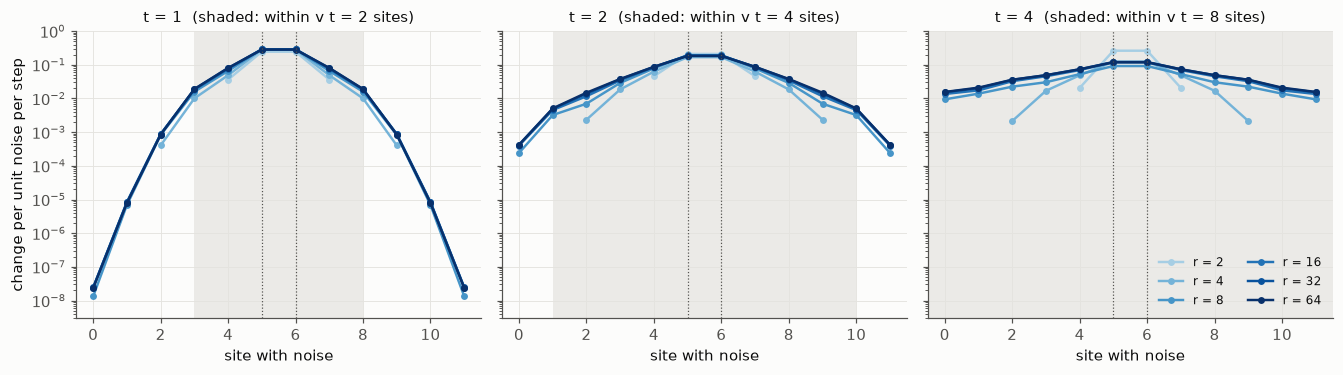

In [29]:
response = pd.read_csv(ROOT / "results/noise_response.csv")
centre = ["Z5", "Z6", "X5", "X6", "Z5Z6", "X5X6"]
plots.noise_reach(response, centre, order=1, save=FIG / "fig6_noise_reach.png");

In [30]:
c = response[response.observable.isin(centre)]
per_step = (c.groupby(["t", "order", "r", "site"]).delta.apply(lambda x: np.sqrt(np.mean(x**2)))
            / (c.p.iloc[0] * c.groupby(["t", "order", "r", "site"]).r.first())).rename("R").reset_index()
per_step["distance"] = np.where(per_step.site <= 5, 5 - per_step.site, per_step.site - 6)
rows = []
for (t, order, r), g in per_step.groupby(["t", "order", "r"]):
    by = g.groupby("distance").R.mean()
    rows.append({"t": t, "order": order, "r": r, "total per step": g.R.sum(),
                 "reach (sites, 1% of peak)": int(by.index[by >= 0.01 * by.max()].max()),
                 "farthest site / observed sites": by.iloc[-1] / by.iloc[0]})
pd.DataFrame(rows).pivot_table(index=["order", "r"], columns="t",
                               values=["total per step", "reach (sites, 1% of peak)"]).round(3)

reach (sites, 1% of peak)           total per step              
t                                1    2    4              1      2      4
order r                                                                  
1     2                        1.0  1.0  1.0          0.562  0.512  0.566
      4                        2.0  3.0  3.0          0.686  0.504  0.382
      8                        2.0  4.0  5.0          0.743  0.618  0.442
      16                       2.0  4.0  5.0          0.766  0.652  0.596
      32                       2.0  4.0  5.0          0.772  0.660  0.630
      64                       2.0  4.0  5.0          0.767  0.657  0.629
2     2                        1.0  1.0  1.0          0.897  0.703  1.101
      4                        2.0  3.0  3.0          0.795  0.807  0.495
      8                        2.0  4.0  5.0          0.782  0.693  0.435
      16                       2.0  4.0  5.0          0.781  0.671  0.581
      32                       2.0  4.0  5.0          0.778  0.665  0.617
      64                       2.0  4.0  5.0          0.770  0.658  0.622

Noise reaches a local observable through the dynamics, not through the circuit. At t = 1 the response falls by seven
orders of magnitude from the observed sites to the chain's ends, and noise more than two sites away contributes under
1% of the peak, at every r from 4 to 64, even though the circuit's light cone has covered the chain since r = 3. The
reach grows with t (2, 4 and 5 sites at t = 1, 2 and 4, the last capped by the chain) and not with r. Past
r ≈ 8 the curves for different r lie on top of each other: each step adds a fixed amount of noise, set by the sites
within about $vt$, and second order gives the same picture.

So the noise term of a local observable is linear in r with an n-independent coefficient, $r^*$ scales as
$\gamma^{-1/(q+1)}$ at any chain length, and Trivedi & Cirac's $\gamma^{-1/(q+d+1)}$ is a property of their bound
rather than of the error. Their other conclusion, that $r^*$ for local observables does not depend on system size,
holds, for the reason the figure shows.

### Fourth order on local observables

In [31]:
def crossover_local(g, metric):
    tab = g.pivot_table(index="noise_scale", columns="order", values=metric).sort_index(ascending=False)
    return crossover(tab)


rows = [{"n": n, "t": t, "local observables": crossover_local(g, "err_local"),
         "state (trace distance)": crossover_local(g, "err_state")}
        for (n, t), g in lopt[lopt.n >= 10].groupby(["n", "t"])]
print("Noise scale at which fourth order catches second (NaN: not by scale 0.01)")
pd.DataFrame(rows).round(3)

Noise scale at which fourth order catches second (NaN: not by scale 0.01)


,n,t,local observables,state (trace distance)
0,10,1,NaN,0.033
1,10,2,NaN,0.033
2,10,4,NaN,0.044
3,12,1,NaN,0.012
4,12,2,NaN,0.022
5,12,4,NaN,0.031


For local observables fourth order never catches second, even on a device 100× better than Torino, at n = 10 and 12.
Their second-order Trotter error is already small, so there is little for fourth order to buy with its 5× gates. For
the state the crossover at n = 10 reproduces section 5 (scale 0.03–0.04); at n = 12 it moves to 0.012–0.031, so it
also depends on the chain length. Section 5's 23–31× is therefore a property of the whole state at n = 10, and for
the observables experiments read out, second order is the right choice over the whole range tested.

### Light-cone patches: r\* on long chains

The noise-response map suggests a cheap way to find $r^*$ on a long chain: simulate only a patch, a sub-chain of w
sites around each observable, on that chain's own physical qubits and under the same noise model, and read each
observable from the patch where it sits farthest from the cut edges (`qtrotter/patches.py`). Exact, Trotterized and
noisy values all come from the patch, so the cost is that of a w-qubit simulation whatever the chain length.

Three checks. On the 12-site chain, patches of 6, 8 and 10 sites against the full density-matrix simulation, at every
time, order (1 and 2) and noise scale. On a 20-site chain, too long for a density matrix, patches against noisy
statevector trajectories of the whole chain (5 batches of 100, at t = 1 around the optimum, today's noise and
10× lower). Then the patches alone on 24 and 96 sites (the transpiler finds a 96-qubit path on Torino, but none of
120).

In [32]:
full12 = lerr[(lerr.source == "noisy") & (lerr.n == 12)].drop(columns="source")
pv = pd.read_csv(ROOT / "results/patches.csv").merge(full12, on=keys, suffixes=("", "_full"))
grid_l = sorted(local_runs.r.unique())
rows = []
for (w, t, order, s), g in pv.groupby(["width", "t", "order", "noise_scale"]):
    g = g.sort_values("r")
    rf = g.r.values[g.rms_full.argmin()]
    near = g[(g.r >= rf / 2) & (g.r <= 2 * rf)]
    rows.append({"width": w, "t": t, "order": order, "noise_scale": s, "r_full": rf,
                 "r_patch": g.r.values[g.rms.argmin()],
                 "curve error near r*": (near.rms / near.rms_full - 1).abs().max()})
check = pd.DataFrame(rows)
check["within one step"] = [within_one_step(a, b, grid_l) for a, b in zip(check.r_patch, check.r_full)]
check["same r*"] = check.r_patch == check.r_full
summary_p = check.groupby(["width", "t"]).agg(same=("same r*", "sum"), within_one=("within one step", "sum"),
                                              cases=("same r*", "size"),
                                              curve_error=("curve error near r*", "median"))
summary_p.round(3)

same  within_one  cases  curve_error
width t                                        
6     1.0     9          10     10        0.086
      2.0     5          10     10        0.190
      4.0     3           4     10        1.304
8     1.0    10          10     10        0.019
      2.0     9          10     10        0.117
      4.0     3           5     10        0.722
10    1.0    10          10     10        0.013
      2.0     9          10     10        0.042
      4.0     9          10     10        0.058

In [33]:
traj = pd.read_csv(ROOT / "results/trajectories.csv")
exact20 = traj[traj.source == "exact"].set_index("observable").value
rows = []
for (order, r, s), g in traj[traj.source == "noisy"].groupby(["order", "r", "noise_scale"]):
    by = g.pivot_table(index="observable", columns="batch", values="value").loc[exact20.index]
    mean, sem2 = by.mean(axis=1), by.var(axis=1, ddof=1) / by.shape[1]
    # Debiased: the batch scatter inflates a mean squared error by the mean squared standard error.
    rows.append({"order": order, "r": r, "noise_scale": s,
                 "rms": np.sqrt(max(np.mean((mean - exact20) ** 2 - sem2), 0.0)),
                 "rms_std": np.sqrt(np.mean(sem2))})
traj_err = pd.DataFrame(rows)
p20 = pd.read_csv(ROOT / "results/patches_20.csv")
cmp20 = traj_err.merge(p20[p20.width == 10][["order", "r", "noise_scale", "rms"]],
                       on=["order", "r", "noise_scale"], suffixes=("", "_patch"))
rows = []
for (order, s), g in cmp20.groupby(["order", "noise_scale"]):
    g = g.sort_values("r")
    rows.append({"order": order, "noise_scale": s, "r* trajectories": g.r.values[g.rms.argmin()],
                 "r* patches": g.r.values[g.rms_patch.argmin()],
                 "error at r*, trajectories": g.rms.min(), "error at r*, patches": g.rms_patch.min(),
                 "statistical error": g.rms_std.median()})
pd.DataFrame(rows).round(4)

,order,noise_scale,r* trajectories,r* patches,"error at r*, trajectories","error at r*, patches",statistical error
0,1,0.1,8,10,0.022,0.022,0.004
1,1,1.0,4,4,0.090,0.085,0.009
2,2,0.1,8,7,0.008,0.008,0.004
3,2,1.0,3,3,0.046,0.041,0.009


RMS error at r*, today's noise: {(24, 1.0, 1): 0.086, (24, 1.0, 2): 0.042, (24, 2.0, 1): 0.105, (24, 2.0, 2): 0.055, (96, 1.0, 1): 0.186, (96, 1.0, 2): 0.161, (96, 2.0, 1): 0.183, (96, 2.0, 2): 0.156}
12-site path: median CZ error 4.4e-03, 0 above 1%, 0 at 1.0
24-site path: median CZ error 4.3e-03, 0 above 1%, 0 at 1.0


96-site path: median CZ error 4.1e-03, 17 above 1%, 6 at 1.0
r* for local observables at today's noise, by chain length


n          6   8   10  12    20  24  96
t   order                              
1.0 1       5   4   4   4     4   4   4
    2       4   3   4   3     3   3   3
2.0 1       8   6   8   7  <NA>   7   6
    2       6   5   5   5  <NA>   5   5

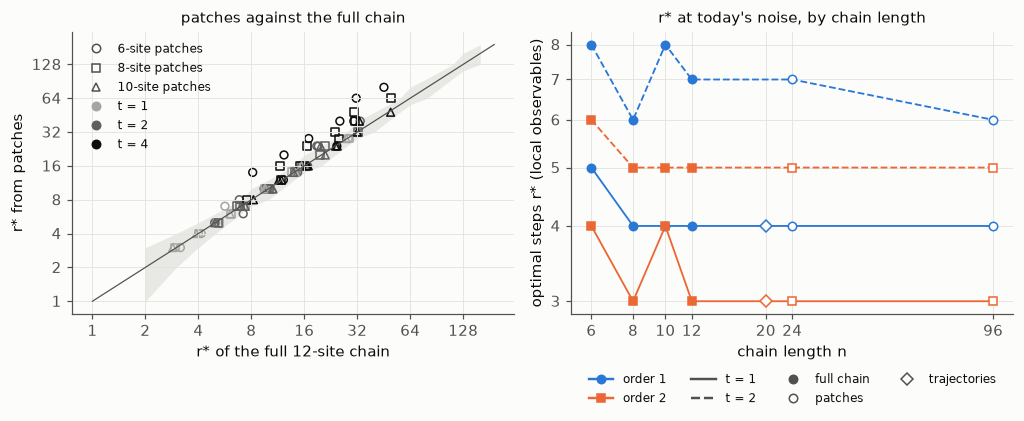

In [34]:
long = pd.read_csv(ROOT / "results/patches_long.csv")
rstar = lambda d, col="rms": d.loc[d.groupby(["n", "t", "order", "noise_scale"])[col].idxmin()]
by_length = pd.concat([
    lopt[(lopt.noise_scale == 1) & (lopt.order <= 2) & (lopt.t <= 2)]
        .rename(columns={"r_local": "r_star"}).assign(source="full")[["n", "t", "order", "r_star", "source"]],
    rstar(traj_err[traj_err.noise_scale == 1].assign(n=20, t=1.0))
        .rename(columns={"r": "r_star"}).assign(source="trajectories")[["n", "t", "order", "r_star", "source"]],
    rstar(long[long.noise_scale == 1])
        .rename(columns={"r": "r_star"}).assign(source="patches")[["n", "t", "order", "r_star", "source"]],
], ignore_index=True)
plots.patch_check(check, by_length, grid_l, save=FIG / "fig7_patches.png")
err_long = rstar(long[long.noise_scale == 1]).set_index(["n", "t", "order"]).rms
print("RMS error at r*, today's noise:", err_long.round(3).to_dict())

# CZ errors along each chain's path on the device
torino = FakeTorino()
for n in (12, 24, 96):
    lay = choose_layout(tfim(n), torino)
    cz = np.array([(torino.target["cz"].get((a, b)) or torino.target["cz"].get((b, a))).error
                   for a, b in zip(lay[:-1], lay[1:])])
    print(f"{n}-site path: median CZ error {np.median(cz):.1e}, {(cz > 0.01).sum()} above 1%, "
          f"{(cz >= 1).sum()} at 1.0")
print("r* for local observables at today's noise, by chain length")
by_length.pivot_table(index=["t", "order"], columns="n", values="r_star").astype("Int64")  # 20 sites: t = 1 only

Patches work once they are wider than the reach of the dynamics. On the 12-site chain at t = 1, every width finds the
full chain's r\* to within a grid step, 8- and 10-site patches exactly in all 10 cases, with error curves within 2% of
the full simulation near the optimum (9% for 6 sites). At t = 2, 10-site patches match r\* in 9 of 10 cases (the tenth
one step off) with curves within 4%; 6-site ones stay within a step, but their curves are off by up to 19%. At t = 4
the light cone is about as long as the chain: 6- and 8-site patches miss by up to four grid steps, and 10-site ones
match only because on 12 sites they nearly are the chain. The noise map gives the rule: leave a margin of the noise's
reach (2 sites at t = 1, 4 at t = 2) on each side of an observable, so $w \approx 2vt + 2$.

On the 20-site chain, too long for a density matrix, the 10-site patches' error differs from the trajectories' by
less than the trajectories' statistical error (the standard error of one observable, 0.003–0.010) at all 30 points,
both orders and both noise levels; the patches run about 5% low at the median, as on 12 sites. They give the same r\*
at today's noise (4 and 3 steps) and land one grid step off at 10× lower noise (10 against 8 at first order, 7 against
8 at second), where both minima are flat to within that error.

At today's noise, r\* for local observables is 4 and 3 steps (first and second order) at t = 1, and 6–7 and 5 at t = 2,
at every length from 8 sites to 96. The error at the optimum does not stay put: it doubles at 96 sites, because the
path the transpiler picks there crosses 17 couplers with CZ error above 1%, six of them at 1.0 (out of service) in
this calibration snapshot. Observables next to them are lost whatever r is, which raises the error floor without moving
the optimum. So choosing r for a 96-qubit experiment takes 10-qubit simulations; choosing the qubits is a separate
problem.

## 7. Limitations

* The sweeps use one noise snapshot (Torino), simulated with Aer's model: gate depolarizing plus thermal relaxation,
  no crosstalk, leakage or drift. On `ibm_kingston` such a model matched the device closely, but that is one chain, one
  evolution time and one day's calibration.
* The hardware check measures local observables only, so it tests the optimum for that metric, not for the state.
  The observable version of the semi-empirical predictor assumes global damping, which overstates the noise there.
* The better-device sweep scales every error rate by one factor, on one 10-qubit chain. Real improvements are uneven
  (two-qubit gates, coherence and idling improve at different rates), which would move the fourth-order crossover.
* The semi-empirical predictor needs the noiseless Trotter error, which is cheap to compute classically only for small
  systems. For local observables, light-cone patches (section 6) lift that limit for evolution times whose light cone
  fits in a patch (t ≤ 2 with 10 sites here).
* Section 6 covers one model (the TFIM) in 1D. Its noise map uses uniform depolarizing noise on ideal gates, and the
  independent 20-qubit check covers t = 1 only.
* r is sampled on a grid, so measured r\* has grid-step resolution (about ±25% at the values found).
* Avtandilyan & Pogosov's constants are order-of-magnitude estimates, and their higher orders use a different
  (complex-coefficient) family from the standard Suzuki formulas used here; only their orders 1 and 2 are compared.
  Knee & Munro evaluate their formula only at first order; the second-order version here is our extension.
* At t = 4 and 10–12 qubits the trace distance at the optimum is 0.77 or more; three fourth-order minima are shallow
  and one is flat.

## References

1. G. C. Knee, W. J. Munro, *Optimal Trotterization in universal quantum simulators under faulty control*,
   Phys. Rev. A 91, 052327 (2015). [arXiv:1502.04536](https://arxiv.org/abs/1502.04536)
2. A. A. Avtandilyan, W. V. Pogosov, *Optimal-order Trotter–Suzuki decomposition for quantum simulation on noisy
   quantum computers*. [arXiv:2405.01131](https://arxiv.org/abs/2405.01131)
3. A. M. Childs, Y. Su, M. C. Tran, N. Wiebe, S. Zhu, *Theory of Trotter error with commutator scaling*,
   Phys. Rev. X 11, 011020 (2021). [arXiv:1912.08854](https://arxiv.org/abs/1912.08854)
4. Y. Kim et al., *Evidence for the utility of quantum computing before fault tolerance*, Nature 618, 500 (2023).
5. J. Xu, C. Zhao, J. Fan, Q. Zhao, *Exponentially decaying quantum simulation error with noisy devices*.
   [arXiv:2504.10247](https://arxiv.org/abs/2504.10247)
6. R. Trivedi, J. I. Cirac, *Noise robustness of problem-to-simulator mappings for quantum many-body physics*.
   [arXiv:2509.17579](https://arxiv.org/abs/2509.17579)